# Database Design Implementation: Scripts, Backup/Restore, Migration and Integrity

**Tool:** SQL Server Management Studio (SSMS) · **Sample databases:** `pubs`, `Northwind` · **Practice database:** `DesignDemo`

This notebook explains how a designed database is **moved, protected and kept correct**. Most steps are clicks in SSMS, so each section lists the wizard steps and every option you can choose, followed by the equivalent T-SQL.

| # | Section | Core question |
|---|---------|---------------|
| 1 | Generate Scripts | How do I turn a database into a portable text file? |
| 2 | Backup / Restore | How do I protect data and recover from failure? |
| 3 | Migration | How do I move a database to another server or version? |
| 4 | Constraints | How do I stop invalid data from entering a table? |
| 5 | Relationships and rules | How do I enforce business logic across tables? |
| 6 | Schema | How are objects organized and secured inside a database? |

> Code cells contain T-SQL for reference. The notebook runs on a Python kernel, so the cells are not executed here.

## 1. Generate Scripts

### What it is
SSMS reads an existing database and writes a **`.sql` text file** that rebuilds it: `CREATE TABLE`, keys, indexes, views, and optionally the data as `INSERT` statements.

### Why we use it
* **Portability:** a text script runs on any compatible SQL Server, no binary file copying.
* **Version control:** a `.sql` file can be committed to GitHub and its changes tracked. A `.bak` file cannot.
* **Targeting another version:** the script can be written for an older or newer server.
* **Sharing and teaching:** this is how sample databases such as `pubs` and `Northwind` are distributed.

### Schema and data
| Choice | Result |
|---|---|
| **Schema only** | structure only (tables, columns, keys): an empty database |
| **Data only** | only `INSERT` statements |
| **Schema and data** | a full copy; fine for small databases, impractical for large ones (use a backup instead) |

### Steps in SSMS

1. In **Object Explorer**, right-click the database (for example `pubs`).
2. Choose **Tasks → Generate Scripts...** The wizard opens.
3. **Introduction** page: read it, click **Next**.
4. **Choose Objects** page. Pick one option:

| Option | Meaning |
|---|---|
| **Script entire database and all database objects** | everything in the database |
| **Select specific database objects** | tick only the tables, views, procedures you want |

5. **Set Scripting Options** page. Choose where the output goes:

| Output option | Meaning |
|---|---|
| **Save as script file** | writes a `.sql` file; choose **Single file** or **Single file per object** |
| **Save to clipboard** | copies the script so you can paste it anywhere |
| **Save to new query window** | opens the script in a new SSMS tab |

   Then click **Advanced** to open the detailed options (next table).
6. **Summary** page: review, then **Next**.
7. **Save or Publish Scripts** page: shows progress and success for each object. Click **Finish**.

### Advanced options worth knowing

| Option | Choices | Meaning |
|---|---|---|
| **Types of data to script** | Schema only / Data only / Schema and data | what goes into the script |
| **Script for Server Version** | a list of SQL Server versions | the oldest server that must be able to run the script |
| **Script for the database engine type** | Stand-alone SQL Server / Azure SQL Database / Azure SQL Managed Instance | target platform |
| **Script DROP and CREATE** | Script CREATE / Script DROP / Script DROP and CREATE | the last one lets you re-run the script safely |
| **Check for object existence** | True / False | adds `IF EXISTS` checks around drops and creates |
| **Script USE DATABASE** | True / False | adds `USE [pubs]` at the top |
| **Script Indexes** | True / False | include indexes |
| **Script Triggers** | True / False | include triggers |
| **Script Primary Keys / Unique Keys / Foreign Keys** | True / False | include each constraint type |
| **Script Check Constraints** | True / False | include `CHECK` constraints |
| **Script Logins / Object-Level Permissions** | True / False | include security settings |
| **Script Statistics** | Do not script / Script statistics / Script statistics and histograms | optimizer statistics |
| **Script Extended Properties** | True / False | descriptions attached to objects |
| **Continue scripting on error** | True / False | keep going if one object fails |

> The exact list depends on the SSMS version, and very old targets such as SQL Server 2000 are no longer offered in recent versions.




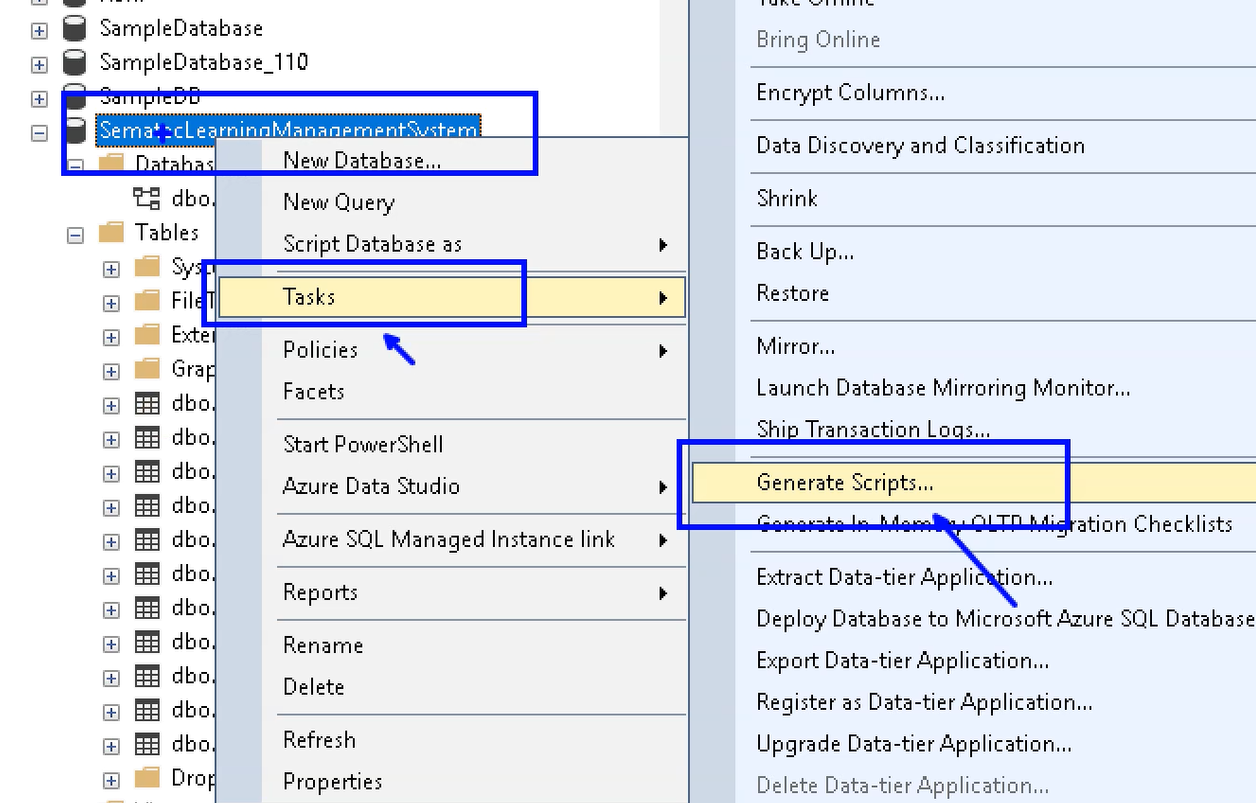

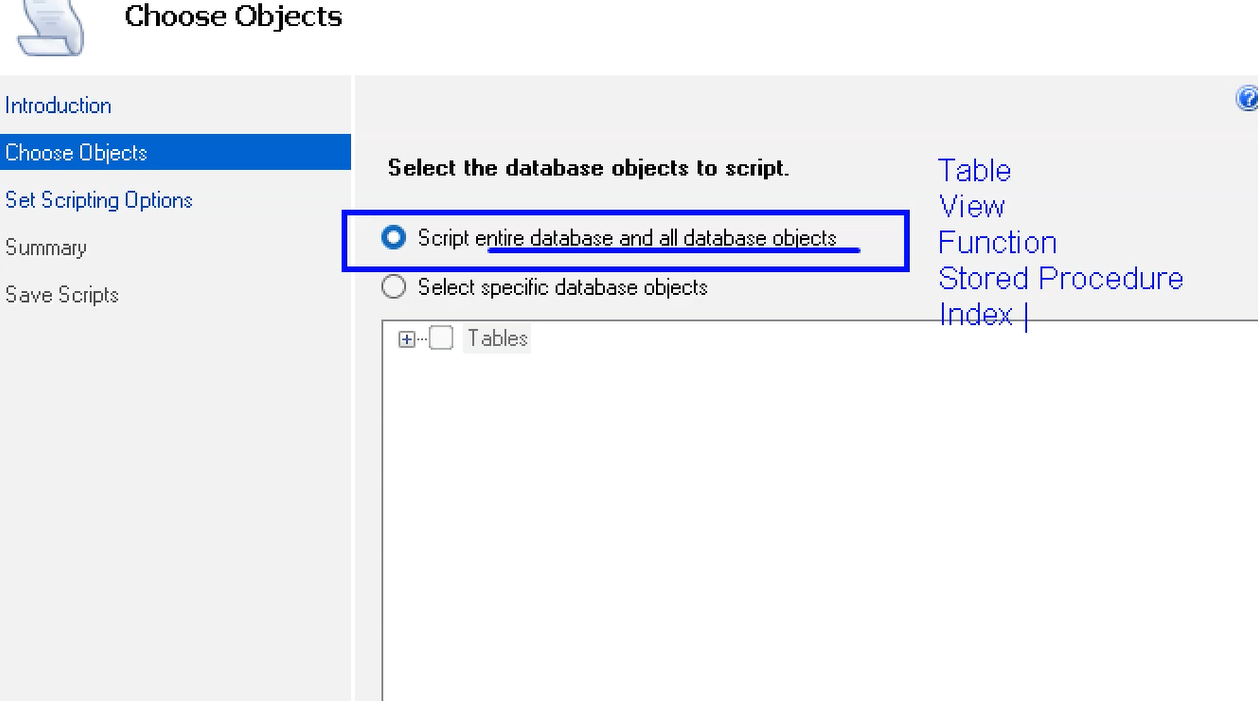

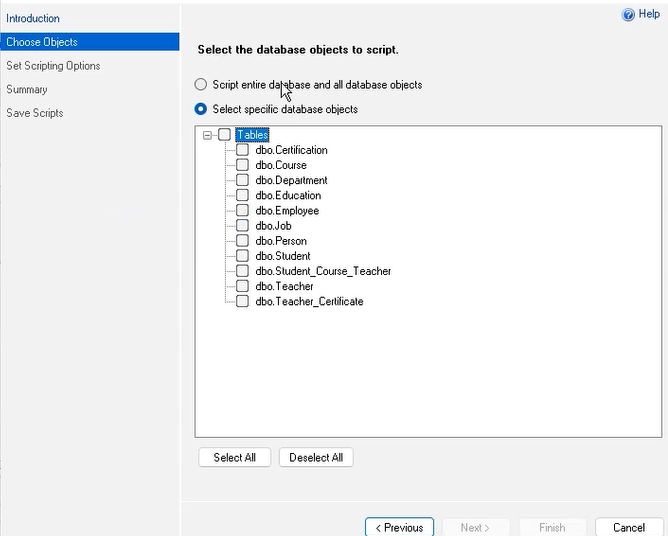

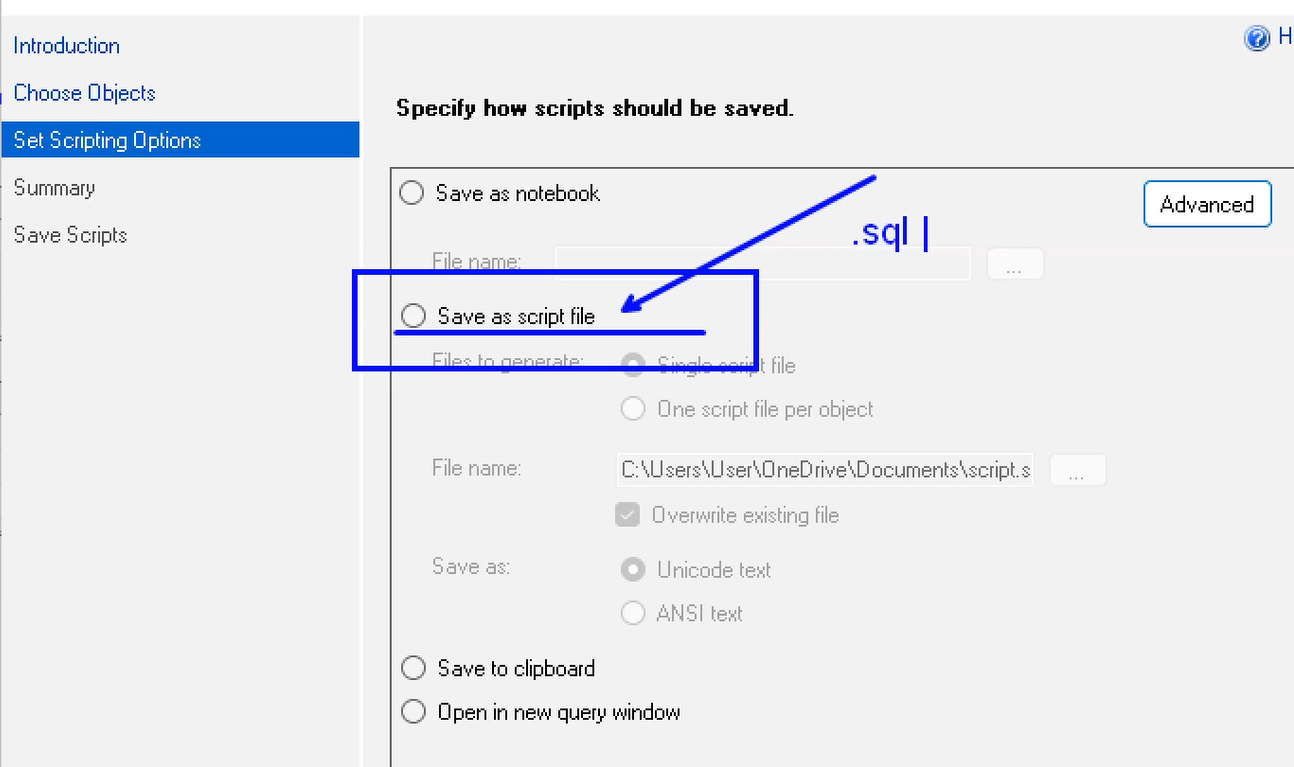

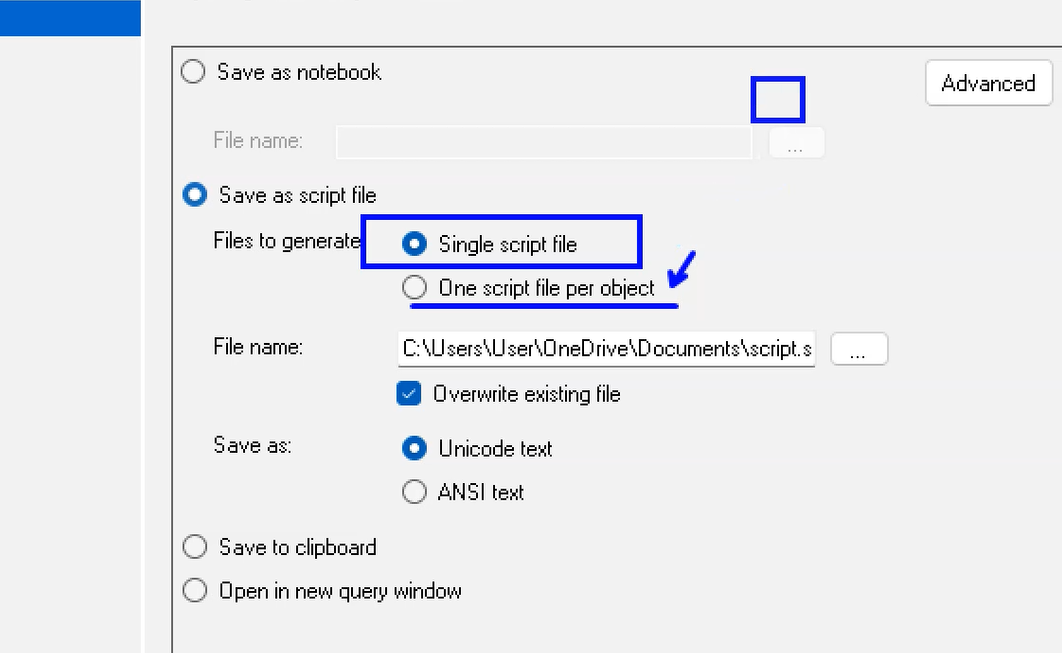

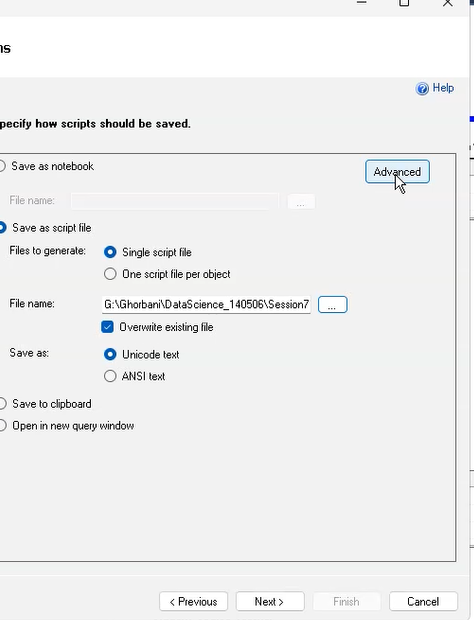

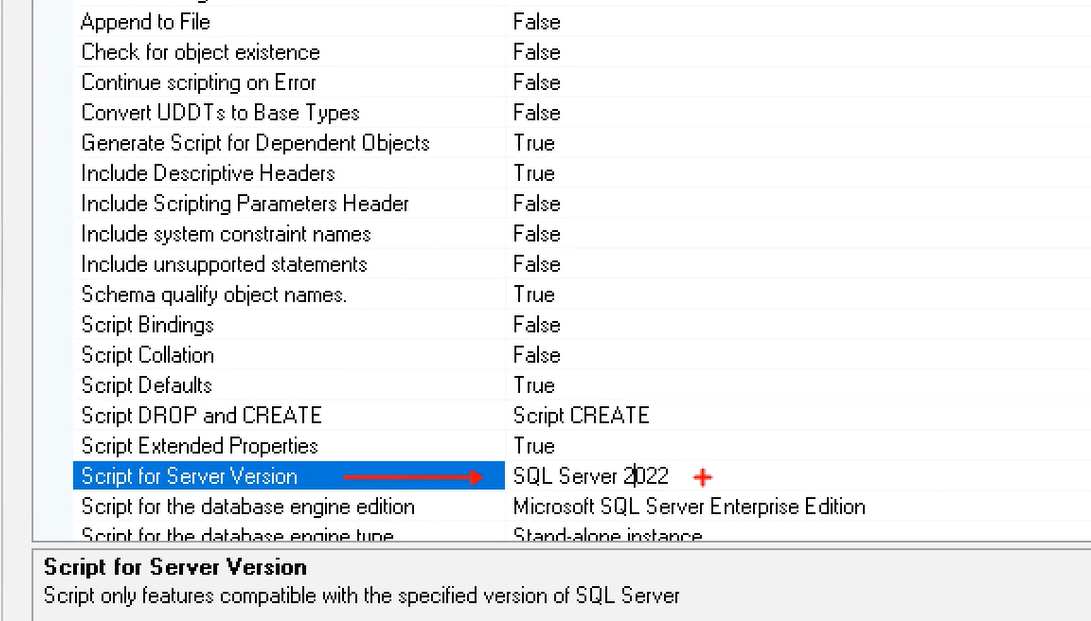

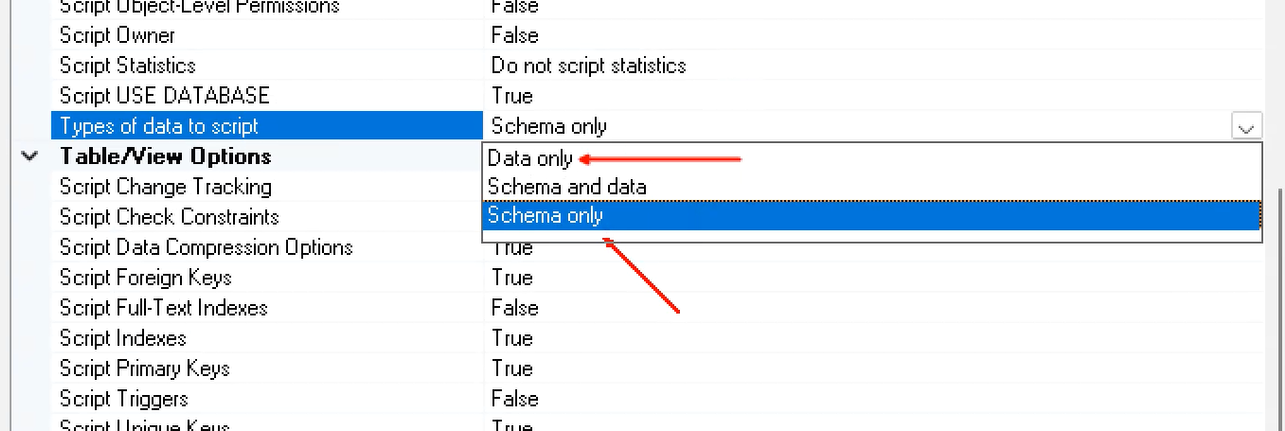

### Backward and forward compatibility

The **Script for Server Version** option controls this.

| Term | Meaning | Example |
|---|---|---|
| **Backward compatibility** | The script is written so an **older** server can run it. Newer features are left out or flagged. | Script a 2022 database for an older server |
| **Forward compatibility** | An **older** script is run on a **newer** server. Newer servers normally accept it, except for removed features. | A script from the 2000 era, run on 2025 |

This is why scripts are the tool for going **down** a version, which backups cannot do (see section 3).

## 2. Backup and Restore

### Who does this?
The **DBA (Database Administrator)**. A data scientist should understand the concepts, because the data being analyzed depends on them.

### What it is
A **backup** is a copy of the database saved to a **`.bak`** file. A **restore** rebuilds the database from that file.

### Why we use it
* recover from hardware failure, corruption or accidental deletion
* undo a mistaken `DELETE` or `UPDATE`
* copy a database to another server (migration)

### The transaction log
SQL Server writes every change to the **transaction log** before applying it. The log makes point-in-time recovery possible.

### Recovery models

| Model | Log behavior | What you can restore |
|---|---|---|
| **Simple** | log is cleared automatically | only to the time of the last full or differential backup |
| **Full** | log is kept until you back it up | **any point in time**, using log backups |
| **Bulk-logged** | like Full, but bulk operations are minimally logged | most points in time, with limits |

### Backup types

| Type | Contains |
|---|---|
| **Full** | the whole database |
| **Differential** | only what changed since the last full backup |
| **Transaction log** | log records since the last log backup (Full or Bulk-logged models only) |

### The three recovery ideas

| Idea | Meaning |
|---|---|
| **Full recovery** | the model that keeps the log, so complete recovery is possible |
| **Point-in-time recovery** | restore to an exact moment, e.g. just before a wrong update; needs a full backup plus log backups |
| **Recovery by transaction** | the log is replayed up to a chosen point: committed transactions are kept, uncommitted ones are rolled back |

### Steps in SSMS: backup

1. Right-click the database → **Tasks → Back Up...**
2. **General** page:

| Option | Choices | Meaning |
|---|---|---|
| **Recovery model** | (read-only) | shows the current model |
| **Backup type** | Full / Differential / Transaction Log | see the table above |
| **Copy-only backup** | tick / untick | a one-off backup that does not disturb the normal backup chain |
| **Backup component** | Database / Files and filegroups | back up everything or only some files |
| **Name / Description** | text | labels stored inside the backup |
| **Backup set will expire** | After *n* days / On date | protects the backup from being overwritten before then |
| **Destination** | Disk / URL | a local or network file, or Azure storage |
| **Add / Remove** | buttons | choose the `.bak` path; several files can share one backup |

3. **Media Options** page:

| Option | Meaning |
|---|---|
| **Back up to the existing media set → Append** | adds a new backup to the same file |
| **Back up to the existing media set → Overwrite** | replaces everything in the file |
| **Back up to a new media set** | starts a new file and erases old content |
| **Verify backup when finished** | reads the backup back to confirm it is readable |
| **Perform checksum before writing to media** | detects corruption while writing |
| **Continue on error** | do not stop at the first error |
| **Transaction log → Truncate** | frees log space after a log backup |
| **Transaction log → Back up the tail of the log** | captures the last log records and leaves the database in the *restoring* state |

4. **Backup Options** page: **Compression** (use server default / compress / do not compress) and **Encryption**.
5. Click **OK**.

### Steps in SSMS: restore

1. Right-click **Databases → Restore Database...**
2. **General** page:

| Option | Choices | Meaning |
|---|---|---|
| **Source → Database** | list | restore from the backup history stored on this server |
| **Source → Device** | `...` button, then **Add** | choose a `.bak` file directly (use this on a new server) |
| **Destination → Database** | name | the database name to create or overwrite |
| **Restore to → Timeline** | Last backup taken / **Specific date and time** | the point-in-time option |
| **Restore plan** | tick boxes | which backup sets to apply (full, then differential, then logs) |
| **Verify Backup Media** | button | checks that the backup is readable before restoring |

3. **Files** page: **Relocate all files to folder** lets you choose new data and log paths, which you need when the new server uses different folders.
4. **Options** page:

| Option | T-SQL equivalent | Meaning |
|---|---|---|
| **Overwrite the existing database** | `WITH REPLACE` | replace a database of the same name |
| **Preserve the replication settings** | `WITH KEEP_REPLICATION` | keep replication configuration |
| **Restrict access to the restored database** | `WITH RESTRICTED_USER` | only administrators can connect afterwards |
| **Leave the database ready to use (RESTORE WITH RECOVERY)** | `WITH RECOVERY` | finish the restore; database goes online |
| **Leave non-operational, and do not roll back (RESTORE WITH NORECOVERY)** | `WITH NORECOVERY` | stay in *restoring* state so more backups can be applied |
| **Leave in read-only mode (RESTORE WITH STANDBY)** | `WITH STANDBY` | read-only access between log restores |
| **Take tail-log backup before restore** | `BACKUP LOG ... WITH NORECOVERY` | saves the last log records so nothing is lost |
| **Close existing connections to destination database** | `SET SINGLE_USER` | disconnects users that block the restore |
| **Prompt before restoring each backup** | | asks you before every backup set |

5. Click **OK**.

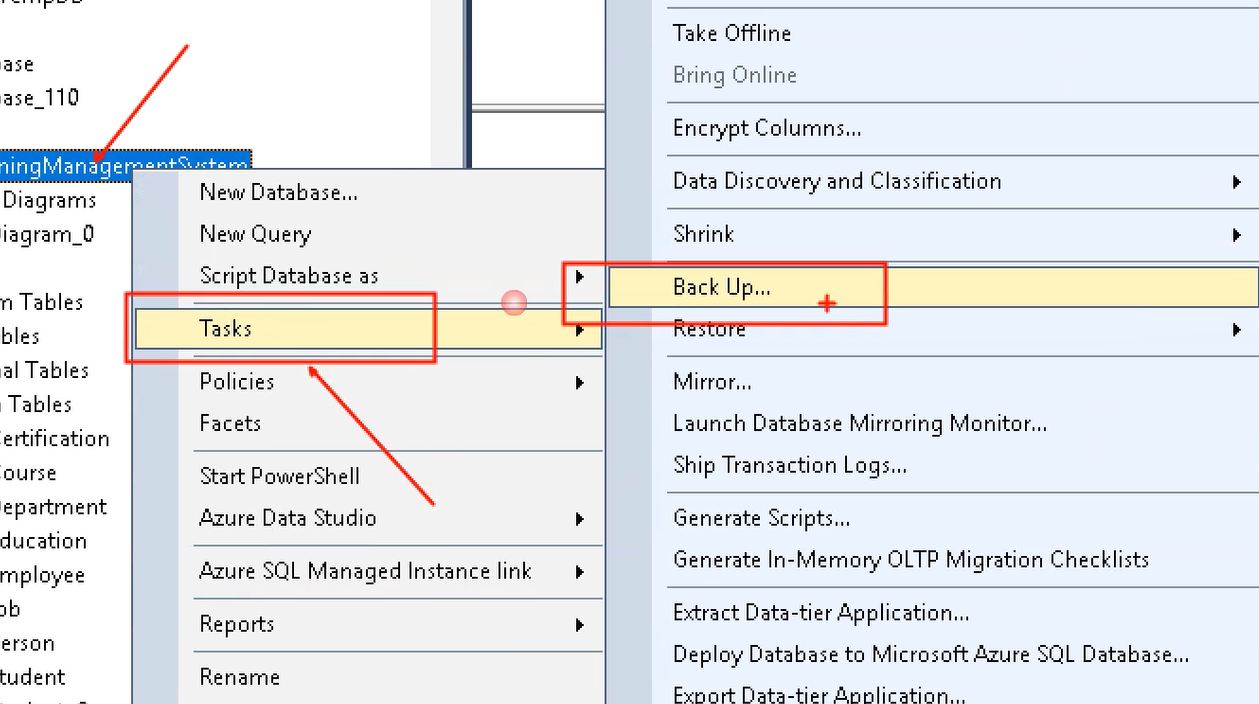

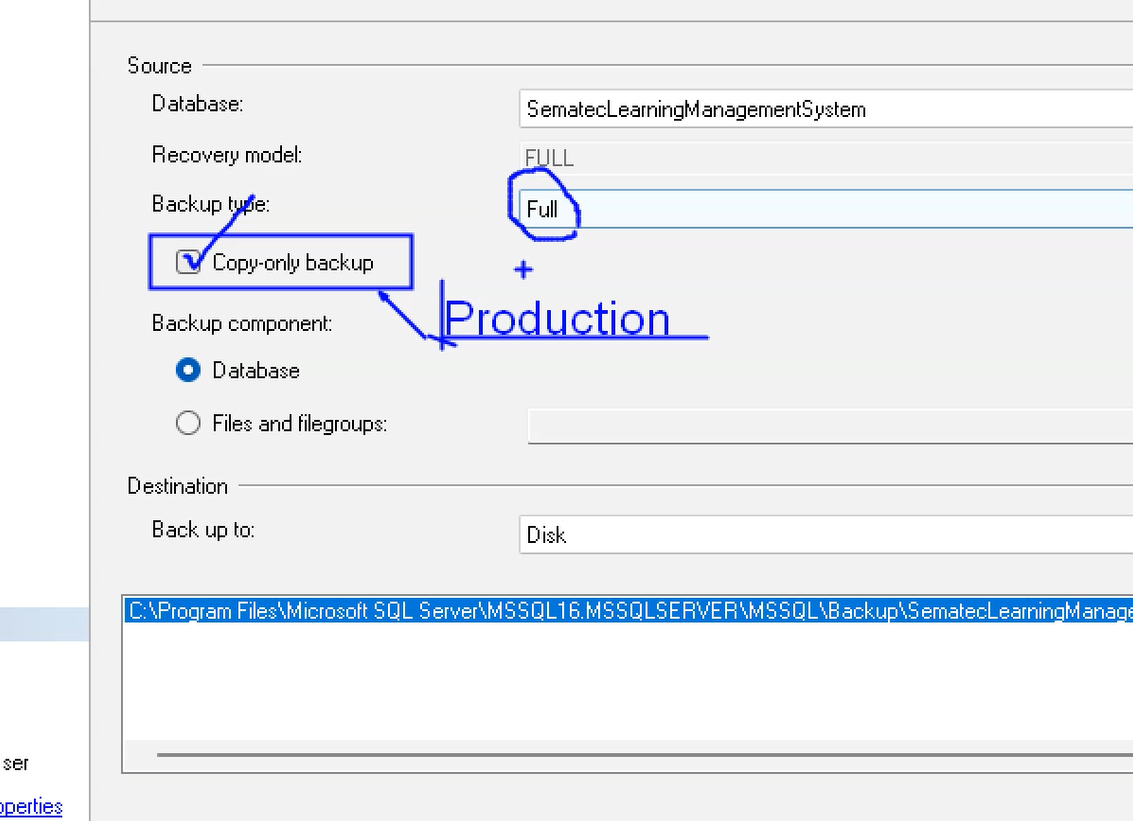

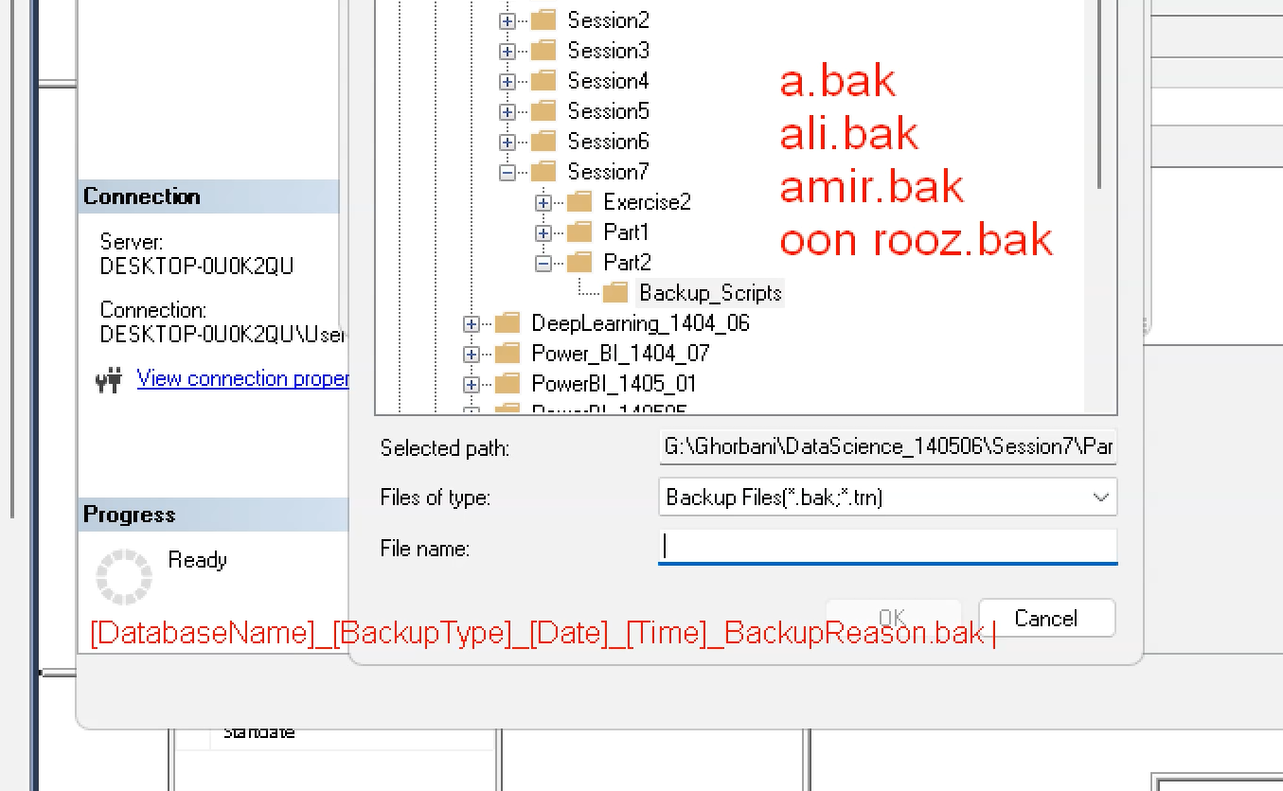

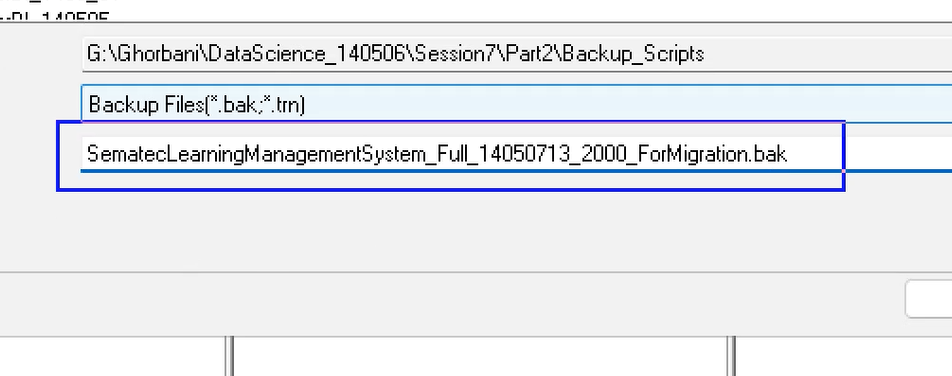

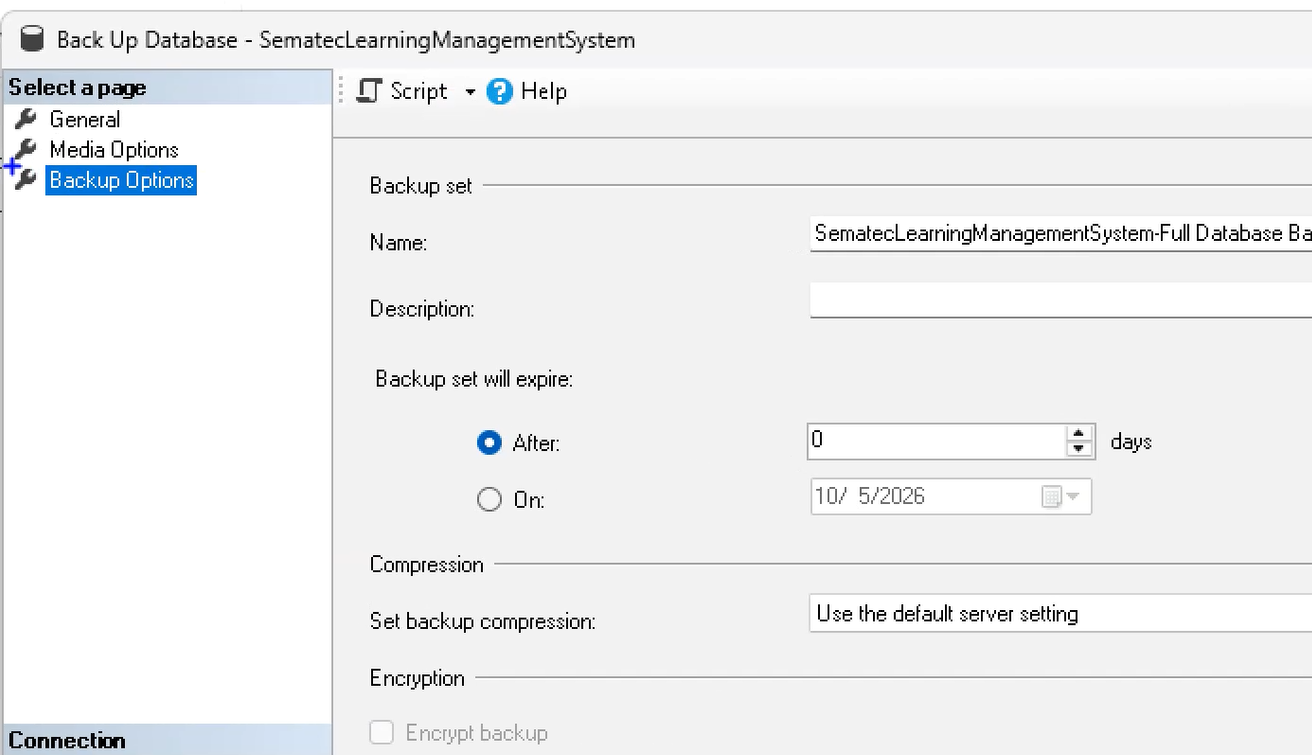

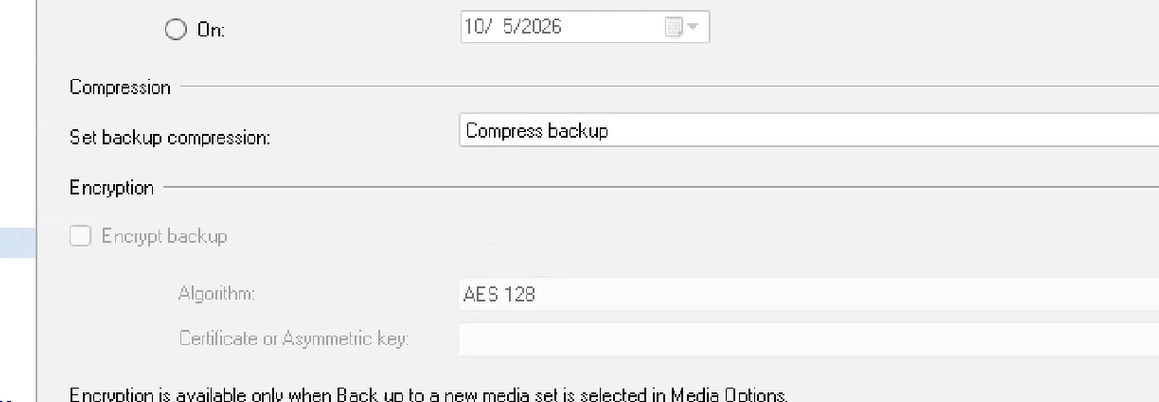

**Expected messages (numbers vary):**

```
RESTORE DATABASE successfully processed 392 pages in 0.041 seconds (74.7 MB/sec).
RESTORE LOG successfully processed 12 pages in 0.012 seconds (7.8 MB/sec).
```

Rules to remember:
* `NORECOVERY` means "more backups are coming": the database stays unusable.
* `RECOVERY` (the default) means "this is the last step": uncommitted transactions are rolled back and the database goes online.
* `STOPAT` rolls forward committed work only up to the chosen time, which gives **recovery by transaction**.

## 3. Migration

### What it is
**Migration** means moving a database to another server or to a newer SQL Server version.

| Method | How it works | Source database during the move |
|---|---|---|
| **Backup / Restore** | back up on the old server, restore on the new one | stays **online** |
| **Detach / Attach** | disconnect the files, copy them, attach them on the new server | **offline** (out of service) |
| **Generate Scripts** | move a text script (schema, optionally data) | stays online |

### Version rule for backups
A backup can be restored on the **same or a newer** version, **never on an older one**.

| Backup taken on | Restore on 2017 | Restore on 2022 | Restore on 2025 |
|---|---|---|---|
| SQL Server 2022 | **fails** | works | works |

To move **down** a version, use **Generate Scripts** with the older target version (backward compatibility).

After restoring an old database on a newer server, it keeps its **old compatibility level**. Raise it deliberately after testing.

### Detach and Attach

**Detach** removes the database from the server but keeps its data file (`.mdf`) and log file (`.ldf`) on disk. While detached, the database is **out of service**.

#### Steps: detach
1. Right-click the database → **Tasks → Detach...**
2. Options in the dialog:

| Option | Meaning |
|---|---|
| **Drop Connections** | disconnects users, otherwise detach fails while sessions are open |
| **Update Statistics** | refreshes optimizer statistics before detaching |
| **Keep Full-text Catalogs** | keeps full-text search data with the files |
| **Status column** | shows *Ready*, or *Not Ready* with a message such as "1 active connection" |

3. Click **OK**.
4. Copy the `.mdf` and `.ldf` files to the new server.

#### Steps: attach
1. On the new server, right-click **Databases → Attach...**
2. Click **Add** and choose the `.mdf` file. The log file is found automatically if it sits next to it.
3. Check the **Database details** list. A *Not found* message on a file means its path is wrong.
4. Optionally change **Attach As** (the database name) and **Owner**.
5. Click **OK**.

Attach is **one-way**: once attached to a newer version, the database is upgraded and cannot return to an older server.

### Which method should I choose?

| Situation | Best choice |
|---|---|
| source must stay in service | Backup / Restore |
| moving to a newer version, downtime acceptable | Detach / Attach or Backup / Restore |
| moving to an **older** version | Generate Scripts |
| small database, changes tracked in GitHub | Generate Scripts |

## 4. Consistency and Integrity: Constraints

### The goal
A database must always hold **correct, consistent** data. **Integrity** is the set of guarantees that make this true, and **constraints** are the rules the database enforces on every insert, update and delete. Application code can contain bugs; a constraint cannot be bypassed.

| Integrity type | Meaning | Enforced by |
|---|---|---|
| **Entity** | every row is uniquely identifiable | `PRIMARY KEY`, `UNIQUE` |
| **Referential** | links between tables are valid | `FOREIGN KEY` |
| **Domain** | values in a column are valid | `NOT NULL`, `CHECK`, `DEFAULT`, data types |

### The five constraints

| Constraint | Enforces | Notes |
|---|---|---|
| **NOT NULL** | the column must have a value | combine with any other constraint |
| **PRIMARY KEY** | uniquely identifies each row | unique and not null; **one per table**; creates a clustered index by default |
| **FOREIGN KEY** | value must exist in another table's key | prevents orphan rows; can cascade deletes and updates |
| **CHECK** | a condition each value must satisfy | e.g. `Price >= 0` |
| **UNIQUE** | no duplicates in the column | **several per table** allowed; accepts a single `NULL` |

### Creating constraints in SSMS (Table Designer)

1. Expand the database → **Tables**, right-click the table → **Design**.
2. **NOT NULL:** in the column grid, untick **Allow Nulls** for the column.
3. **PRIMARY KEY:** select the column (or Ctrl+click several), then right-click → **Set Primary Key** (or click the key icon).
4. **UNIQUE:** menu **Table Designer → Indexes/Keys... → Add**, then set:

| Property | Setting |
|---|---|
| **Columns** | the column to protect |
| **Is Unique** | Yes |
| **Type** | Unique Key |

5. **CHECK:** menu **Table Designer → Check Constraints... → Add**, then type the **Expression**, for example `Price >= 0`.
6. **FOREIGN KEY:** menu **Table Designer → Relationships... → Add**, open **Tables and Columns Specification**, choose the parent table and key column and the child column, then set:

| Property | Choices | Meaning |
|---|---|---|
| **Enforce Foreign Key Constraint** | Yes / No | turn checking on or off |
| **Delete Rule** | No Action / Cascade / Set Null / Set Default | what happens to children when a parent is deleted |
| **Update Rule** | No Action / Cascade / Set Null / Set Default | what happens to children when a parent key changes |

7. Press **Ctrl+S** to save the table.

**Seeing relationships as a picture:** expand the database → **Database Diagrams → New Database Diagram** (SSMS may offer to create supporting objects the first time, choose Yes), add the tables, and drag a column from one table onto another to create a relationship.

## 5. Rules and Relationships

### Business rules
A **rule** is a statement about the business, for example *"every book belongs to exactly one publisher"* or *"a book can have several authors"*. In design, rules are implemented through **relationships** between tables, mainly with foreign keys.

| Type | Meaning | How it is built | Example in `pubs` |
|---|---|---|---|
| **One-to-many (1:N)** | one parent row, many child rows | foreign key in the child table | one publisher, many titles |
| **Many-to-many (M:N)** | many on both sides | a **bridge table** with two foreign keys | titles and authors, linked by `titleauthor` |
| **One-to-one (1:1)** | one row on each side | foreign key that is also unique | one employee, one badge record |

Constraints are the reason joins work reliably: every `pub_id` in `titles` is guaranteed to exist in `publishers`.

### `CREATE RULE` (legacy)
SQL Server also has a separate object `CREATE RULE` that restricts values in a column. It is **deprecated**. Microsoft recommends `CHECK` constraints, which are part of the table definition. Know that it exists, but write `CHECK` constraints.

## 6. Schema

The word has two related meanings:

1. **Design meaning:** the structure of the database (tables, columns, keys, relationships). This is what *Schema only* means in Generate Scripts.
2. **Object meaning:** a **container (namespace)** that groups objects. In `dbo.titles`, `dbo` is the schema and `titles` is the table.

Why use schemas?

| Reason | Example |
|---|---|
| **Organization** | group related tables as `Sales`, `HR`, `Finance` |
| **Security** | grant permissions on a whole schema at once |
| **Name clarity** | two tables can share a name if they are in different schemas |

In SSMS: **Databases → (database) → Security → Schemas** shows them; right-click → **New Schema...** creates one.